In [34]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\siami\ENGR 418 Project\battery-life-cycle\.venv\Scripts\python.exe
3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]


imports and project paths

In [35]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from soc.data import split_frames
from soc.features import feature_columns
from soc.metrics import soc_metrics
from soc.models import FNN

print("project root:", ROOT)

project root: c:\Users\siami\ENGR 418 Project\battery-life-cycle


In [36]:
cfg = yaml.safe_load(open(ROOT / "configs" / "default.yaml"))
data = pd.read_parquet(ROOT / cfg["processed_path"])
splits = split_frames(data, cfg["split"])

for name, df in splits.items():
    print(f"{name:5s}: {df.run_id.nunique()} runs, {len(df):,} rows")

train: 36 runs, 231,428 rows
val  : 5 runs, 35,728 rows
test : 23 runs, 175,874 rows


In [37]:
MODEL_DIR = ROOT / "outputs" / "fnn" / "seed42"
ckpt = torch.load(MODEL_DIR / "model.pt", map_location="cpu", weights_only=False)

cols = ckpt["features"]
mean = np.asarray(ckpt["scaler"]["mean"])
std = np.asarray(ckpt["scaler"]["std"])
mcfg = ckpt["config"]

model = FNN(len(cols), mcfg["hidden"], mcfg.get("dropout", 0))
model.load_state_dict(ckpt["state_dict"])
model.eval()

print("features:", cols)
print("hidden layers:", mcfg["hidden"])

features: ['voltage', 'current', 'temp_c', 'v_avg_30s', 'i_avg_30s', 'v_avg_120s', 'i_avg_120s', 'v_avg_300s', 'i_avg_300s']
hidden layers: [64, 64, 32]


In [38]:
def predict_array(x):
    x = (x - mean) / std
    x = torch.tensor(x, dtype=torch.float32)
    with torch.no_grad():
        return model(x).numpy().reshape(-1)

def predict(df):
    return predict_array(df[cols].to_numpy())

test = splits["test"].copy()
test["soc_pred"] = predict(test)
test["err"] = (test["soc_pred"] - test["soc"]) * 100
test["abs_err"] = test["err"].abs()
test["t_min"] = test["time_s"] / 60

test[["run_id", "t_min", "soc", "soc_pred", "err"]].head()

,run_id,t_min,soc,soc_pred,err
0,n20degC_610_HWFET,0.000000,0.999982,0.991996,-0.798612
1,n20degC_610_HWFET,0.016667,0.999970,0.991038,-0.893200
2,n20degC_610_HWFET,0.033333,0.999952,0.990255,-0.969755
3,n20degC_610_HWFET,0.050000,0.999916,0.989110,-1.080606
4,n20degC_610_HWFET,0.066667,0.999779,0.985971,-1.380783


In [39]:
import json

saved = json.load(open(MODEL_DIR / "metrics.json"))

for t, g in test.groupby("ambient_c"):
    now = soc_metrics(g["soc"], g["soc_pred"])["rmse_pct"]
    before = saved["test_by_temp"][str(t)]["rmse_pct"]
    print(f"{t:>4} °C   now {now:.3f}   saved {before:.3f}")

overall = soc_metrics(test["soc"], test["soc_pred"])["rmse_pct"]
print(f"overall  now {overall:.3f}   saved {saved['test']['rmse_pct']:.3f}")


 -20 °C   now 3.380   saved 3.380


 -10 °C   now 2.253   saved 2.253
   0 °C   now 1.456   saved 1.456
  10 °C   now 1.456   saved 1.456
  25 °C   now 1.602   saved 1.602
  40 °C   now 1.503   saved 1.503
overall  now 1.928   saved 1.928


In [40]:
#confirming the sampling period (data check)
step_s = 1 / cfg["resample_hz"]
print("configured sample period:", step_s, "s")

gaps = test.groupby("run_id")["time_s"].diff().dropna()
print(gaps.value_counts().head())

configured sample period: 1.0 s
time_s
1.0     175820
2.0         29
16.0         1
4.0          1
Name: count, dtype: int64


Section 1: where in the run does the error happen?

In [41]:
def label_segments(df, rest_current=0.05, min_rest_s=60):
    """Split each run into: early 0-5 min, early 5-10 min, middle, rest tail.

    rest tail = final stretch after the last |current| > rest_current,
                counted only if it lasts at least min_rest_s seconds.
    """
    segment = pd.Series("middle", index=df.index)
    for run_id, g in df.groupby("run_id"):
        moving = g[g["current"].abs() > rest_current]
        if moving.empty:
            print(f"WARNING: {run_id} never exceeds {rest_current} A - no rest tail assigned")
            is_rest = pd.Series(False, index=g.index)
        else:
            last_moving_time = moving["time_s"].max()
            is_rest = g["time_s"] > last_moving_time
            rest_duration = g["time_s"].max() - last_moving_time
            if rest_duration < min_rest_s:
                is_rest[:] = False          # too short to count as a rest period
        segment.loc[g.index[is_rest]] = "rest tail"
        segment.loc[g.index[(~is_rest) & (g["t_min"] < 10)]] = "early 5-10"
        segment.loc[g.index[(~is_rest) & (g["t_min"] < 5)]] = "early 0-5"
    return segment

test["segment"] = label_segments(test)
test["segment"].value_counts()

segment
middle        148292
rest tail      13800
early 5-10      6900
early 0-5       6882
Name: count, dtype: int64

In [42]:
#Checking the final resting period (rest tail) of each battery test run to see:
#1. How many data points are in the resting period.
#2. What the maximum absolute current is during that period.
#3. How much the battery's State of Charge (SOC) changes during that period.
#4. Which battery runs do not have a detected resting period.

tail = test[test["segment"] == "rest tail"]
check_tail = tail.groupby("run_id").agg(
    tail_samples=("time_s", "size"),
    tail_start_s=("time_s", "min"),
    tail_end_s=("time_s", "max"),
    max_abs_current=("current", lambda s: s.abs().max()),
    soc_change_pts=("soc", lambda s: (s.max() - s.min()) * 100),
)
check_tail["tail_duration_s"] = check_tail["tail_end_s"] - check_tail["tail_start_s"] + step_s
check_tail["missing_samples"] = check_tail["tail_duration_s"] / step_s - check_tail["tail_samples"]

print(check_tail.drop(columns=["tail_start_s", "tail_end_s"]).round(3).to_string())
print("\nruns with no rest tail:", sorted(set(test["run_id"]) - set(check_tail.index)))

                   tail_samples  max_abs_current  soc_change_pts  tail_duration_s  missing_samples
run_id                                                                                            
0degC_589_HWFET             600              0.0             0.0            600.0              0.0
0degC_589_LA92              600              0.0             0.0            600.0              0.0
0degC_589_UDDS              600              0.0             0.0            600.0              0.0
0degC_589_US06              600              0.0             0.0            600.0              0.0
10degC_567_US06             600              0.0             0.0            600.0              0.0
10degC_576_HWFET            600              0.0             0.0            600.0              0.0
10degC_576_UDDS             600              0.0             0.0            600.0              0.0
10degC_582_LA92             600              0.0             0.0            600.0              0.0
25degC_551

In [43]:
#Error per segment, cold vs warm ambient temperature

ORDER = ["early 0-5", "early 5-10", "middle", "rest tail"]
rows = []
for t, g in test.groupby("ambient_c"):
    total_sq = (g["err"] ** 2).sum()
    for s in ORDER:
        h = g[g["segment"] == s]
        rows.append({
            "ambient_c": t,
            "segment": s,
            "minutes": len(h) * step_s / 60,
            "rmse": np.sqrt((h["err"] ** 2).mean()),
            "mean_signed": h["err"].mean(),
            "share_%": 100 * (h["err"] ** 2).sum() / total_sq,
        })
seg = pd.DataFrame(rows)

def show(value, title, digits=2):
    print(title)
    print(seg.pivot(index="ambient_c", columns="segment", values=value)[ORDER].round(digits))
    print()

show("rmse", "RMSE per segment (SOC points)")
show("share_%", "Share of each temperature's total squared error (%)", 1)
show("mean_signed", "Mean signed error (+ = over-estimate, - = under-estimate)")
show("minutes", "Minutes of data per segment (all test runs at that temperature)", 0)

RMSE per segment (SOC points)
segment    early 0-5  early 5-10  middle  rest tail
ambient_c                                          
-20             8.30        4.91    2.53       2.67
-10             3.47        3.13    2.14       1.95
 0              2.40        2.06    1.41       0.80
 10             2.16        1.97    1.40       1.37
 25             2.03        1.43    1.59       1.62
 40             2.69        2.22    1.42       1.28

Share of each temperature's total squared error (%)
segment    early 0-5  early 5-10  middle  rest tail
ambient_c                                          
-20             37.0        13.0    42.3        7.7
-10             10.4         8.5    74.5        6.6
 0              10.7         7.9    79.1        2.3
 10              7.8         6.6    79.2        6.4
 25              4.8         2.4    86.7        6.1
 40             10.8         7.4    76.9        4.9

Mean signed error (+ = over-estimate, - = under-estimate)
segment    early 0-5  earl

In [44]:
#voltage relaxation vs prediction drift during rest
#Voltage relaxation: How much voltage changes during zero-current rest.
#Prediction stability: Whether your FNN predicts SOC changes when actual SOC is constant.
#Temperature dependence: Whether this behaviour is more pronounced at −20°C and −10°C than at warmer temperatures.

rows = []
rest = test[test["segment"] == "rest tail"]
for run_id, g in rest.groupby("run_id"):
    g = g.sort_values("time_s")
    drift = (g["soc_pred"].iloc[-1] - g["soc_pred"].iloc[0]) * 100
    rows.append({
        "run_id": run_id,
        "ambient_c": g["ambient_c"].iloc[0],
        "v_rise_mV": (g["voltage"].iloc[-1] - g["voltage"].iloc[0]) * 1000,
        "pred_drift_pts": drift,
        "abs_pred_drift_pts": abs(drift),
    })
relax = pd.DataFrame(rows).sort_values(["ambient_c", "run_id"])

print(relax.round(2).to_string(index=False))
print("\nAverage per temperature:")
print(relax.groupby("ambient_c")[["v_rise_mV", "pred_drift_pts", "abs_pred_drift_pts"]].mean().round(2))
print("\nCorrelation between voltage rise and prediction drift:",
      round(relax["v_rise_mV"].corr(relax["pred_drift_pts"]), 2))

           run_id  ambient_c  v_rise_mV  pred_drift_pts  abs_pred_drift_pts
n20degC_610_HWFET        -20     480.77            3.55                3.55
 n20degC_610_LA92        -20     318.97            0.27                0.27
 n20degC_610_UDDS        -20     170.32            0.95                0.95
 n20degC_610_US06        -20     451.41            0.28                0.28
n10degC_596_HWFET        -10     275.12            2.61                2.61
 n10degC_596_LA92        -10     271.81            0.29                0.29
 n10degC_596_UDDS        -10     110.94            0.51                0.51
 n10degC_601_US06        -10     320.68           -0.51                0.51
  0degC_589_HWFET          0     263.89           -1.09                1.09
   0degC_589_LA92          0     172.39           -1.80                1.80
   0degC_589_UDDS          0      60.56           -0.65                0.65
   0degC_589_US06          0     350.46           -1.10                1.10
  10degC_567

how does the model’s error change minute by minute from the start of a run, and how does that differ by temperature?

The three graphs and the table below each have a role:
-Cold vs 25 °C: compares -20,-10,0 temp against room temp.
-Warm vs 25 °C: compares 10,40 temp against room temp.
-All six: the overall trend comparison.
-Table (first 5 min vs 5–60 min, plus ratio): error comparison

In [45]:
#setup for plotting error curves

temps = sorted(test["ambient_c"].unique())
color_of = dict(zip(temps, plt.cm.coolwarm(np.linspace(0, 1, len(temps)))))
REF = 25
FIG_DIR = ROOT / "outputs" / "diagnosis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def error_curve(t):
    """Rows for one temperature (no rest tail, first 60 min) and mean |error| per 1-min bin."""
    g = test[
        (test["ambient_c"] == t)
        & (test["segment"] != "rest tail")
        & (test["t_min"] < 60)
    ]
    return g, g.groupby(g["t_min"].floordiv(1))["abs_err"].mean()

# one y-axis range shared by all three graphs, so they can be compared fairly
Y_MAX = max(error_curve(t)[1].max() for t in temps) * 1.05

def plot_temps(panel_temps, title, filename, ref_dashed=True):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for t in panel_temps:
        _, binned = error_curve(t)
        dashed = ref_dashed and t == REF
        ax.plot(binned.index, binned.values, color=color_of[t],
                lw=2.2 if t < 0 else 1.4, ls="--" if dashed else "-", label=f"{t} °C")
    ax.axvspan(0, 5, color="grey", alpha=0.15, label="300 s window filling")
    ax.set_ylim(0, Y_MAX)
    ax.set_xlabel("time from start of run (min)")
    ax.set_ylabel("mean |error| (SOC points)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

print("shared y-axis max:", round(Y_MAX, 2))

shared y-axis max: 8.07


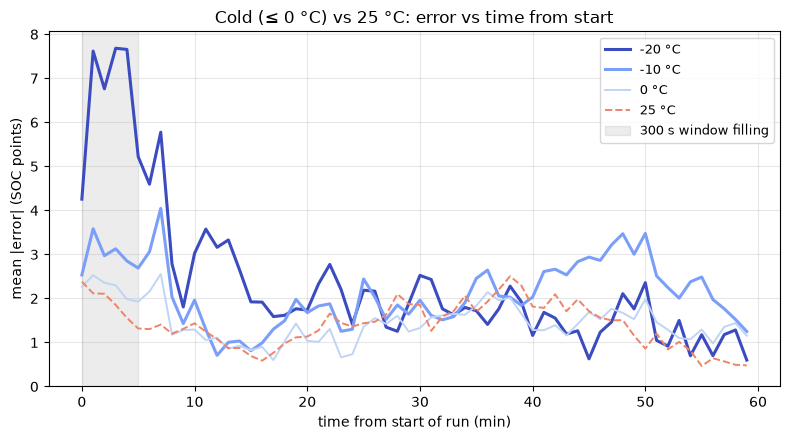

In [46]:
#graph 1, cold vs 25 °C

plot_temps([-20, -10, 0, REF],
           "Cold (≤ 0 °C) vs 25 °C: error vs time from start",
           "error_vs_time_cold.png")

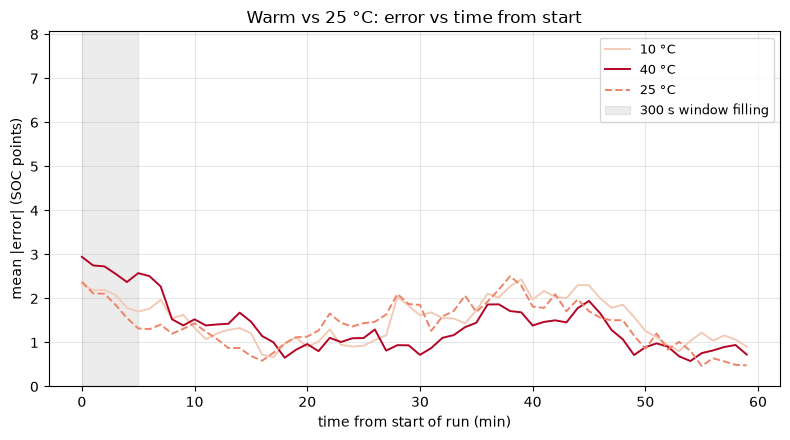

In [47]:
#graph 2, warm vs 25 °C

plot_temps([10, 40, REF],
           "Warm vs 25 °C: error vs time from start",
           "error_vs_time_warm.png")

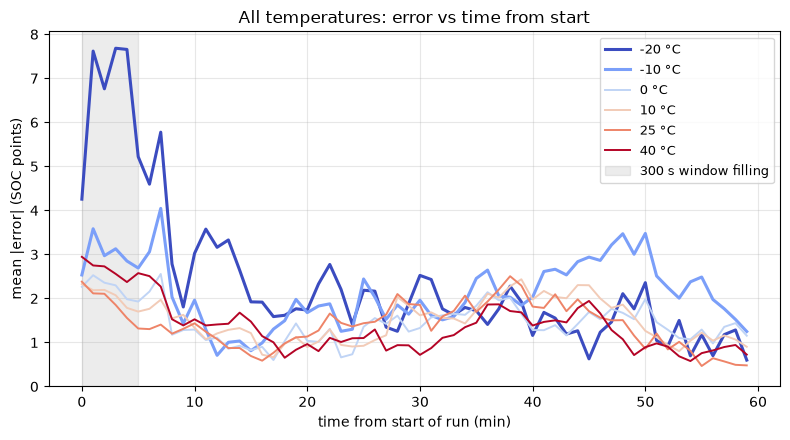

In [48]:
#graph 3, all six temperatures

plot_temps(temps,
           "All temperatures: error vs time from start",
           "error_vs_time_all.png",
           ref_dashed=False)

In [49]:
# Summary of MAE for early vs. later time periods

summary = []
for t in temps:
    g, _ = error_curve(t)
    early_mae = g.loc[g["t_min"] < 5, "abs_err"].mean()
    later_mae = g.loc[g["t_min"] >= 5, "abs_err"].mean()
    summary.append({"ambient_c": t,
                    "MAE first 5 min": early_mae,
                    "MAE 5-60 min": later_mae,
                    "ratio early/later": early_mae / later_mae})
early_vs_later = pd.DataFrame(summary).set_index("ambient_c")
print(early_vs_later.round(3))

           MAE first 5 min  MAE 5-60 min  ratio early/later
ambient_c                                                  
-20                  6.795         2.114              3.214
-10                  3.013         2.011              1.498
 0                   2.286         1.387              1.649
 10                  2.109         1.475              1.430
 25                  2.002         1.377              1.454
 40                  2.671         1.263              2.115


Section 2: deep dive into −20 °C HWFET (the worst run)

In [52]:
#find the HWFET runs and the worst moment at −20 °C


def run_of(temp, cycle):
    ids = test.loc[
        (test["ambient_c"] == temp) &
        (test["cycle"] == cycle),
        "run_id"
    ].unique()

    if len(ids) != 1:
        raise ValueError(
            f"Expected 1 {cycle} run at {temp}°C, "
            f"found {len(ids)}: {list(ids)}"
        )

    return ids[0]


# Automatically find all available HWFET temperatures
hw_temps = sorted(
    test.loc[test["cycle"] == "HWFET", "ambient_c"].unique()
)

hw = {t: run_of(t, "HWFET") for t in hw_temps}

print(f"{len(hw)} HWFET runs:")

for t, rid in hw.items():
    print(f"  {t:>5} °C  {rid}")


# Analyze -20°C HWFET
g_all = test[test["run_id"] == hw[-20]]

# Exclude final resting period
g = g_all[g_all["segment"] != "rest tail"]

if g.empty:
    raise ValueError(
        f"No drive-cycle samples in {hw[-20]} "
        f"(segments found: {g_all['segment'].unique().tolist()})"
    )


# Identify worst predictions
worst = g.loc[g["abs_err"].idxmax()]
worst_all = g_all.loc[g_all["abs_err"].idxmax()]

same_worst = worst.name == worst_all.name

print(
    "\nWorst moment same with and without rest tail:",
    same_worst
)

print("\nWorst moment, -20°C HWFET (drive cycle):")

print(
    f"  time       {worst['time_s']:.0f} s "
    f"({worst['t_min']:.2f} min), "
    f"segment = {worst['segment']}"
)

print(
    f"  SOC        true {worst['soc']*100:.2f}% "
    f"pred {worst['soc_pred']*100:.2f}% "
    f"signed error {worst['err']:+.2f} pt"
)

print(
    f"  voltage    {worst['voltage']:.3f} V "
    f"(300 s mean {worst['v_avg_300s']:.3f} V)"
)

print(
    f"  current    {worst['current']:.2f} A "
    f"(300 s mean {worst['i_avg_300s']:.2f} A)"
)

print(
    f"  cell temp  {worst['temp_c']:.2f} °C"
)

5 HWFET runs:
    -20 °C  n20degC_610_HWFET
    -10 °C  n10degC_596_HWFET
      0 °C  0degC_589_HWFET
     10 °C  10degC_576_HWFET
     40 °C  40degC_556_HWFET

Worst moment same with and without rest tail: True

Worst moment, -20°C HWFET (drive cycle):
  time       135 s (2.25 min), segment = early 0-5
  SOC        true 95.73% pred 77.22% signed error -18.51 pt
  voltage    3.904 V (300 s mean 3.640 V)
  current    0.21 A (300 s mean -1.89 A)
  cell temp  -19.03 °C


Minimum voltage across test data: 2.798 V
Minimum voltage at -20°C: 2.798 V
Minimum voltage for -20°C HWFET: 2.799 V


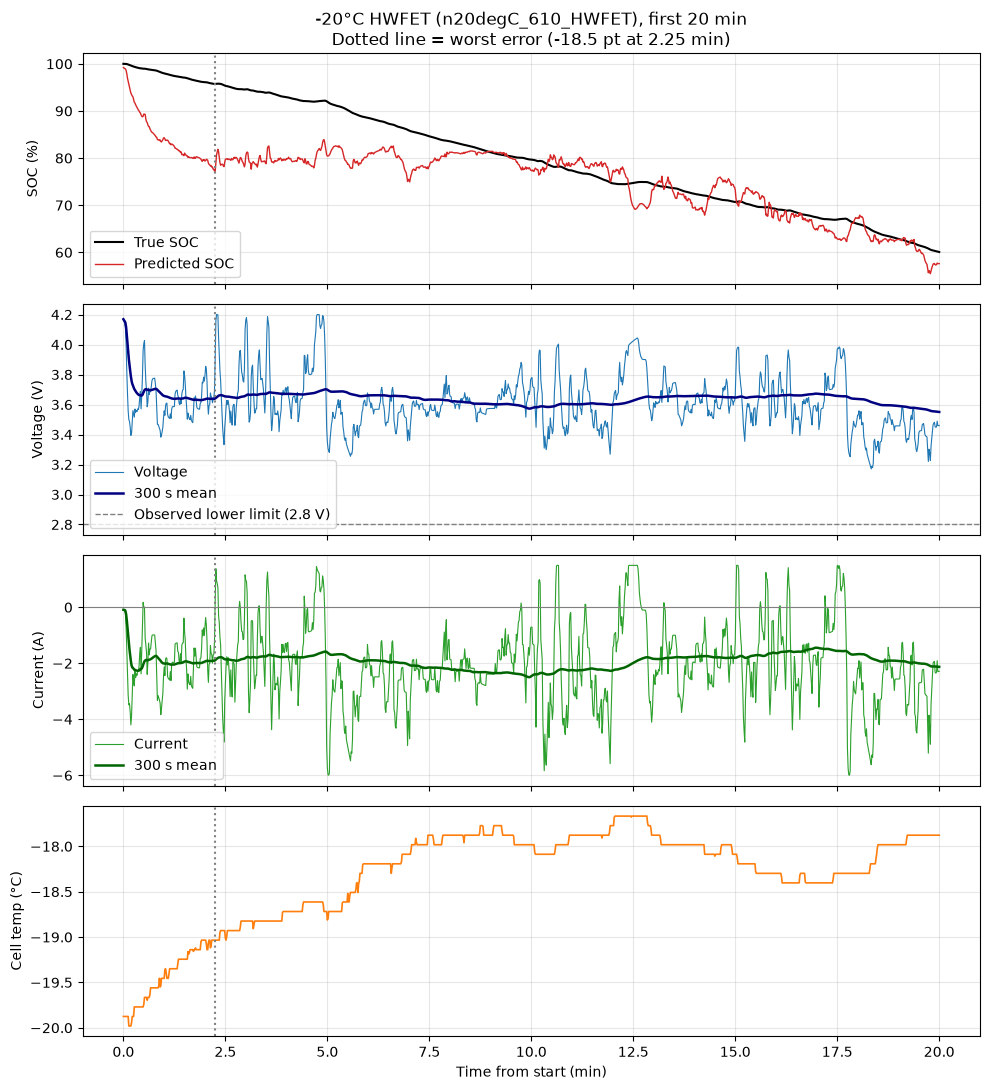

In [55]:
#−20 °C HWFET, first 20 minutes, four panels

WINDOW_MIN = 20
V_OBS = 2.8  # lowest voltage reached in the data (protocol limit, to confirm in dataset readme)
t_w = worst["t_min"]

# Verify measured voltage range
print(f"Minimum voltage across test data: {test['voltage'].min():.3f} V")
print(f"Minimum voltage at -20°C: "
      f"{test.loc[test['ambient_c'] == -20, 'voltage'].min():.3f} V")
print(f"Minimum voltage for -20°C HWFET: {g_all['voltage'].min():.3f} V")

# Ensure the worst error falls inside the plotting window
if not (0 <= t_w <= WINDOW_MIN):
    raise ValueError(
        f"Worst error at {t_w:.2f} min is outside "
        f"the 0–{WINDOW_MIN} min window."
    )

# Select active drive-cycle data and sort chronologically
d = g_all[
    (g_all["t_min"] <= WINDOW_MIN)
    & (g_all["segment"] != "rest tail")
].sort_values("time_s")

if d.empty:
    raise ValueError("No drive-cycle data available in the selected window.")

if worst.name not in d.index:
    raise ValueError("Worst-error sample is not in the selected data.")

# Create four vertically stacked plots
fig, axes = plt.subplots(4, 1, figsize=(10, 11), sharex=True)

# 1) True vs predicted SOC
ax = axes[0]
ax.plot(d["t_min"], d["soc"] * 100,
        color="black", lw=1.5, label="True SOC")
ax.plot(d["t_min"], d["soc_pred"] * 100,
        color="tab:red", lw=1, label="Predicted SOC")
ax.set_ylabel("SOC (%)")
ax.legend(loc="lower left")

# 2) Voltage
ax = axes[1]
ax.plot(d["t_min"], d["voltage"],
        color="tab:blue", lw=0.8, label="Voltage")
ax.plot(d["t_min"], d["v_avg_300s"],
        color="navy", lw=1.8, label="300 s mean")
ax.axhline(V_OBS, color="gray", ls="--", lw=1,
           label="Observed lower limit (2.8 V)")
ax.set_ylabel("Voltage (V)")
ax.legend(loc="lower left")

# 3) Current
ax = axes[2]
ax.plot(d["t_min"], d["current"],
        color="tab:green", lw=0.8, label="Current")
ax.plot(d["t_min"], d["i_avg_300s"],
        color="darkgreen", lw=1.8, label="300 s mean")
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("Current (A)")
ax.legend(loc="lower left")

# 4) Cell temperature
ax = axes[3]
ax.plot(d["t_min"], d["temp_c"],
        color="tab:orange", lw=1.2)
ax.set_ylabel("Cell temp (°C)")
ax.set_xlabel("Time from start (min)")

# Mark the worst prediction moment on all panels
for ax in axes:
    ax.axvline(t_w, color="gray", ls=":", lw=1.5)
    ax.grid(alpha=0.3)

# Set title
axes[0].set_title(
    f"-20°C HWFET ({hw[-20]}), first {WINDOW_MIN} min\n"
    f"Dotted line = worst error "
    f"({worst['err']:+.1f} pt at {t_w:.2f} min)"
)

# Save and display
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.tight_layout()
fig.savefig(
    FIG_DIR / "deep_dive_m20C_HWFET.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

HWFET comparability, first 20 min of drive cycle:
        Start time (min)  End time (min)  SOC start (%)  V start (V)  T start - ambient (°C)  Mean I (A)  RMS I (A)  Max discharge (A)  Max regen (A)  Net Ah out  Gross Ah out  Common samples  Corr I vs 10 °C  RMSE I vs 10 °C (A)
temp_c                                                                                                                                                                                                                               
-20                  0.0            20.0         99.998        4.169                   0.125      -2.001      2.458              5.999          1.498       0.667         0.694            1201            0.974                0.418
-10                  0.0            20.0         99.999        4.176                   0.010      -1.856      2.327              6.338          2.999       0.619         0.653            1201            0.992                0.211
 0                   0.0      

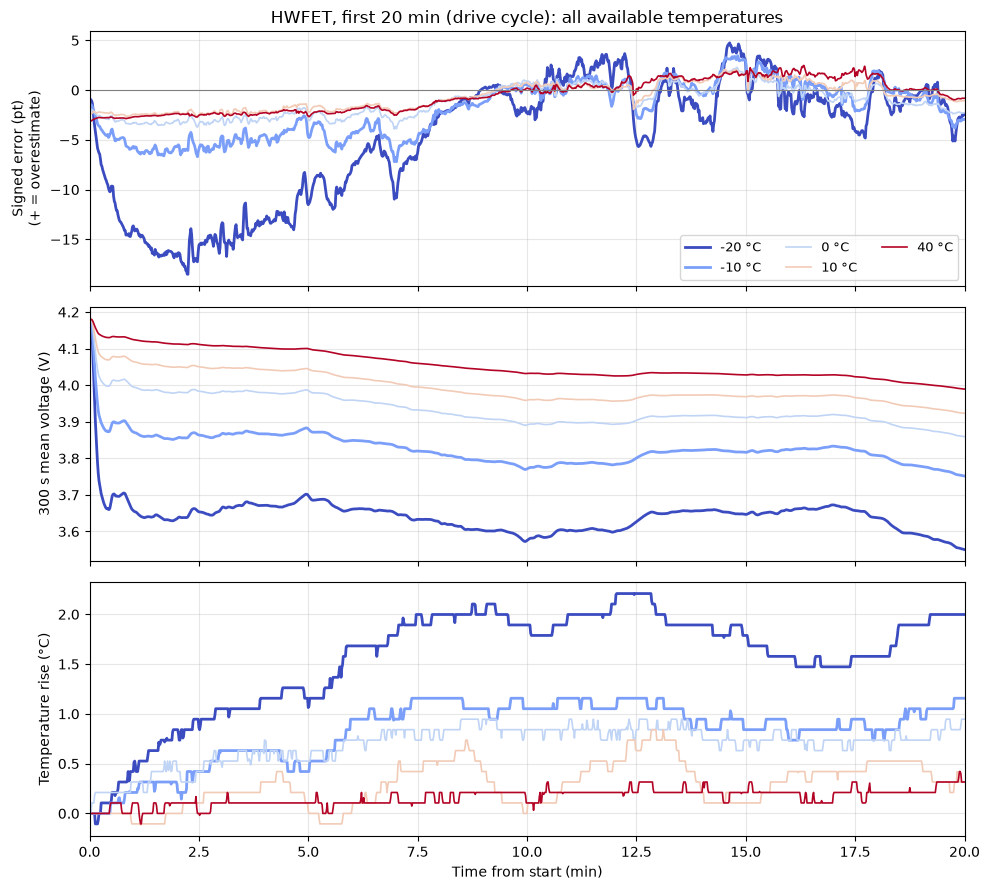

In [56]:

# ---------- Comparability check ----------

REF_T = 10  # Warm reference: HWFET exists here and current is not capped

# Check that the reference temperature exists
if REF_T not in hw_temps:
    raise ValueError(
        f"Reference temperature {REF_T} °C has no HWFET run"
    )

# Every HWFET temperature needs a colour
missing = [t for t in hw_temps if t not in color_of]
if missing:
    raise KeyError(f"color_of has no colour for: {missing}")


def hw_window(t):
    """Return the first WINDOW_MIN minutes of active HWFET data, sorted by time."""
    r = test[
        (test["run_id"] == hw[t])
        & (test["segment"] != "rest tail")
        & (test["t_min"] <= WINDOW_MIN)
    ].sort_values("time_s").copy()

    if r.empty:
        raise ValueError(
            f"No drive-cycle data in the first {WINDOW_MIN} min of {hw[t]}"
        )

    # Validate timestamps
    if r["time_s"].isna().any():
        raise ValueError(f"Missing timestamps in {hw[t]}")

    if r["time_s"].duplicated().any():
        raise ValueError(f"Duplicate timestamps in {hw[t]}")

    return r


# Extract HWFET runs for all temperatures
runs = {t: hw_window(t) for t in hw_temps}

# Reference current profile
ref_i = runs[REF_T].set_index("time_s")["current"]

# ---------- Calculate comparability metrics ----------

rows = []

for t, r in runs.items():

    # Current profile for this run
    i = r.set_index("time_s")["current"]

    # Find timestamps shared with the reference run
    common = i.index.intersection(ref_i.index)

    # Current-profile correlation and RMSE
    if len(common) >= 2:
        actual = i.loc[common]
        reference = ref_i.loc[common]

        corr_val = actual.corr(reference)

        current_rmse = np.sqrt(
            ((actual - reference) ** 2).mean()
        )
    else:
        corr_val = np.nan
        current_rmse = np.nan

    # Net charge removed (Ah)
    # Assumes negative current represents discharge
    ah_net_out = -np.trapezoid(
        r["current"].to_numpy(),
        r["time_s"].to_numpy()
    ) / 3600

    # Gross discharged charge (Ah), excluding regeneration
    ah_discharge = np.trapezoid(
        np.maximum(-r["current"].to_numpy(), 0),
        r["time_s"].to_numpy()
    ) / 3600

    rows.append({
        "temp_c": t,
        "Start time (min)": r["t_min"].iloc[0],
        "End time (min)": r["t_min"].iloc[-1],
        "SOC start (%)": r["soc"].iloc[0] * 100,
        "V start (V)": r["voltage"].iloc[0],
        "T start - ambient (°C)": r["temp_c"].iloc[0] - t,
        "Mean I (A)": r["current"].mean(),
        "RMS I (A)": np.sqrt((r["current"] ** 2).mean()),
        "Max discharge (A)": max(0, -r["current"].min()),
        "Max regen (A)": max(0, r["current"].max()),
        "Net Ah out": ah_net_out,
        "Gross Ah out": ah_discharge,
        "Common samples": len(common),
        f"Corr I vs {REF_T} °C": corr_val,
        f"RMSE I vs {REF_T} °C (A)": current_rmse,
    })


# Create and print the comparability table
comp = pd.DataFrame(rows).set_index("temp_c").round(3)

print(f"HWFET comparability, first {WINDOW_MIN} min of drive cycle:")
print(comp.to_string())


# ---------- Overlay of all HWFET temperatures ----------

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for t, r in runs.items():

    kw = dict(
        color=color_of[t],
        lw=2 if t < 0 else 1.2,
        label=f"{t:g} °C"
    )

    # 1) Signed SOC prediction error
    axes[0].plot(
        r["t_min"],
        r["err"],
        **kw
    )

    # 2) 300-second moving-average voltage
    axes[1].plot(
        r["t_min"],
        r["v_avg_300s"],
        **kw
    )

    # 3) Cell temperature rise from start
    axes[2].plot(
        r["t_min"],
        r["temp_c"] - r["temp_c"].iloc[0],
        **kw
    )


# ---------- Plot formatting ----------

axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Signed error (pt)\n(+ = overestimate)")

axes[1].set_ylabel("300 s mean voltage (V)")

axes[2].set_ylabel("Temperature rise (°C)")
axes[2].set_xlabel("Time from start (min)")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xlim(0, WINDOW_MIN)

axes[0].legend(
    loc="lower right",
    ncol=3,
    fontsize=9
)

axes[0].set_title(
    f"HWFET, first {WINDOW_MIN} min (drive cycle): "
    f"all available temperatures"
)


# ---------- Save and display ----------

FIG_DIR.mkdir(parents=True, exist_ok=True)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "hwfet_compare_temps.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [58]:
#first-10-minute table per temperature, focuses on error, voltage and temperature in the first 10 minutes.

FIRST_MIN = 10
EDGE_S = 30   # seconds averaged at the start and end of the window (reduces jitter)
rows = []

for t, r in runs.items():
    f = r[r["t_min"] <= FIRST_MIN]
    if f.empty:
        raise ValueError(f"No data in the first {FIRST_MIN} min of {hw[t]}")

    t0, t1 = f["time_s"].iloc[0], f["time_s"].iloc[-1]
    start = f[f["time_s"] < t0 + EDGE_S]
    end = f[f["time_s"] > t1 - EDGE_S]

    true_drop = (start["soc"].mean() - end["soc"].mean()) * 100
    pred_drop = (start["soc_pred"].mean() - end["soc_pred"].mean()) * 100

    worst_f = f.loc[f["abs_err"].idxmax()]

    rows.append({
        "temp_c": t,
        "MAE (pt)": f["abs_err"].mean(),
        "P95 |err| (pt)": f["abs_err"].quantile(0.95),
        "Mean signed (pt)": f["err"].mean(),
        "Worst signed (pt)": worst_f["err"],
        "Worst at (min)": worst_f["t_min"],
        "True SOC drop (pt)": true_drop,
        "Pred SOC drop (pt)": pred_drop,
        "Pred/true drop": pred_drop / true_drop if true_drop != 0 else np.nan,
        "V start (V)": f["voltage"].iloc[0],
        "V min (V)": f["voltage"].min(),
        "V drop (V)": f["voltage"].iloc[0] - f["voltage"].min(),
        "Mean V 300s (V)": f["v_avg_300s"].mean(),
        "Max discharge (A)": max(0, -f["current"].min()),
        "Temp rise (°C)": f["temp_c"].iloc[-1] - f["temp_c"].iloc[0],
    })

first10 = pd.DataFrame(rows).set_index("temp_c").round(3)
print(f"HWFET, first {FIRST_MIN} min of drive cycle "
      f"(SOC drops use {EDGE_S} s averages at each end):")
print(first10.to_string())

HWFET, first 10 min of drive cycle (SOC drops use 30 s averages at each end):
        MAE (pt)  P95 |err| (pt)  Mean signed (pt)  Worst signed (pt)  Worst at (min)  True SOC drop (pt)  Pred SOC drop (pt)  Pred/true drop  V start (V)  V min (V)  V drop (V)  Mean V 300s (V)  Max discharge (A)  Temp rise (°C)
temp_c                                                                                                                                                                                                                               
-20        9.229          16.593            -9.204            -18.510           2.250              19.465              14.874           0.764        4.169      3.255       0.914            3.657              5.994           1.893
-10        4.083           6.288            -4.048             -7.196           6.967              13.498               9.855           0.730        4.176      3.560       0.616            3.850              6.248           1.052
 0